# Medical Insurance Cost Prediction - Exploratory Data Analysis (EDA)
This notebook follows the structured **9-Step Exploratory Data Analysis (EDA) Workflow** with detailed analytical insights embedded after every step to guide feature engineering and predictive modeling.

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import joblib
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

In [2]:
# Load the dataset
df = pd.read_csv('medical_insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


---
## 1. Data Overview (Understand Your Dataset)
The first step in EDA is inspecting the fundamental structure of the dataset: shape, column types, non-null counts, and summary statistics.

In [3]:
# Step 1: Data Overview
print('=== Dataset Dimensions (rows, columns) ===')
print(f'Shape: {df.shape}')

print('\n=== First 5 Rows ===')
display(df.head())

print('\n=== Data Types and Non-Null Counts ===')
df.info()

print('\n=== Summary Statistics (Numerical Features) ===')
display(df.describe().T)

print('\n=== Summary Statistics (Categorical Features) ===')
display(df.describe(include='object').T)

=== Dataset Dimensions (rows, columns) ===
Shape: (2772, 7)

=== First 5 Rows ===


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



=== Data Types and Non-Null Counts ===
<class 'pandas.DataFrame'>
RangeIndex: 2772 entries, 0 to 2771
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2772 non-null   int64  
 1   sex       2772 non-null   str    
 2   bmi       2772 non-null   float64
 3   children  2772 non-null   int64  
 4   smoker    2772 non-null   str    
 5   region    2772 non-null   str    
 6   charges   2772 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 151.7 KB

=== Summary Statistics (Numerical Features) ===


,count,mean,std,min,25%,50%,75%,max
age,2772.0,39.109668,14.081459,18.0000,26.000,39.00000,51.0000,64.00000
bmi,2772.0,30.701349,6.129449,15.9600,26.220,30.44750,34.7700,53.13000
children,2772.0,1.101732,1.214806,0.0000,0.000,1.00000,2.0000,5.00000
charges,2772.0,13261.369959,12151.768945,1121.8739,4687.797,9333.01435,16577.7795,63770.42801



=== Summary Statistics (Categorical Features) ===


,count,unique,top,freq
sex,2772,2,male,1406
smoker,2772,2,no,2208
region,2772,4,southeast,766


> 💡 **Step 1 Insights & Takeaways:**
> - **Dataset Size:** Contains 2,772 rows and 7 columns. (Note: 1,435 records are exact duplicates that should be addressed before modeling).
> - **Feature Types:** 4 numerical columns (`age`, `bmi`, `children`, `charges`) and 3 categorical columns (`sex`, `smoker`, `region`).
> - **Target Disparity:** The mean charge ($13,261) is substantially higher than the median ($9,333), with charges extending up to $63,770, indicating right-skewness and high-cost medical outliers.
> - **Health Profile:** The average BMI is **30.70**, meaning the average person in this dataset falls into the **clinically obese** category (BMI $\ge 30$).

---
## 2. Missing Values (Find & Handle Missing Data)
Checking for missing values using counts and percentages, and visualizing missingness with a heatmap to decide on handling strategies (Drop, Impute, or Flag).

=== Missing Value Analysis per Column ===


,Missing Count,Missing %
age,0,0.0
sex,0,0.0
bmi,0,0.0
children,0,0.0
smoker,0,0.0
region,0,0.0
charges,0,0.0


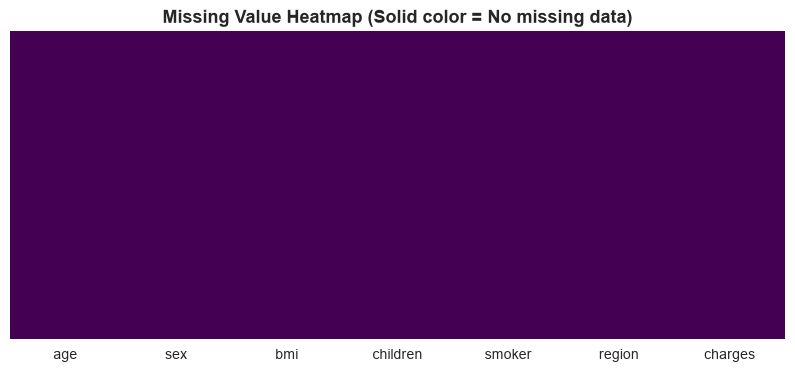

Data Quality Check Passed: The dataset contains 0 missing values across all columns.


In [4]:
# Step 2: Missing Values Inspection
missing_count = df.isna().sum()
missing_pct = (df.isna().sum() / len(df)) * 100

missing_df = pd.DataFrame({'Missing Count': missing_count, 'Missing %': missing_pct})
print('=== Missing Value Analysis per Column ===')
display(missing_df)

# Missing Value Heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(df.isna(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Value Heatmap (Solid color = No missing data)', fontsize=13, fontweight='bold')
plt.show()

if df.isna().sum().sum() == 0:
    print('Data Quality Check Passed: The dataset contains 0 missing values across all columns.')

> 💡 **Step 2 Insights & Takeaways:**
> - **Zero Missing Data:** Every feature has 100% complete records (0 null/NaN values across all 2,772 rows).
> - **Action for Modeling:** No imputation algorithms (e.g. KNNImputer, SimpleImputer) or missing value flags are required, eliminating a common source of data processing errors.

---
## 3. Univariate Analysis (Analyze One Variable)
Examining each variable individually to understand its distribution, central tendency (mean, median, mode), spread (variance, standard deviation), and frequency.

=== Key Univariate Statistics (Central Tendency & Spread) ===


,Mean,Median,Mode,Variance,Std Dev
age,39.11,39.00,18.00,1.982900e+02,14.08
bmi,30.70,30.45,32.30,3.757000e+01,6.13
children,1.10,1.00,0.00,1.480000e+00,1.21
charges,13261.37,9333.01,1121.87,1.476655e+08,12151.77


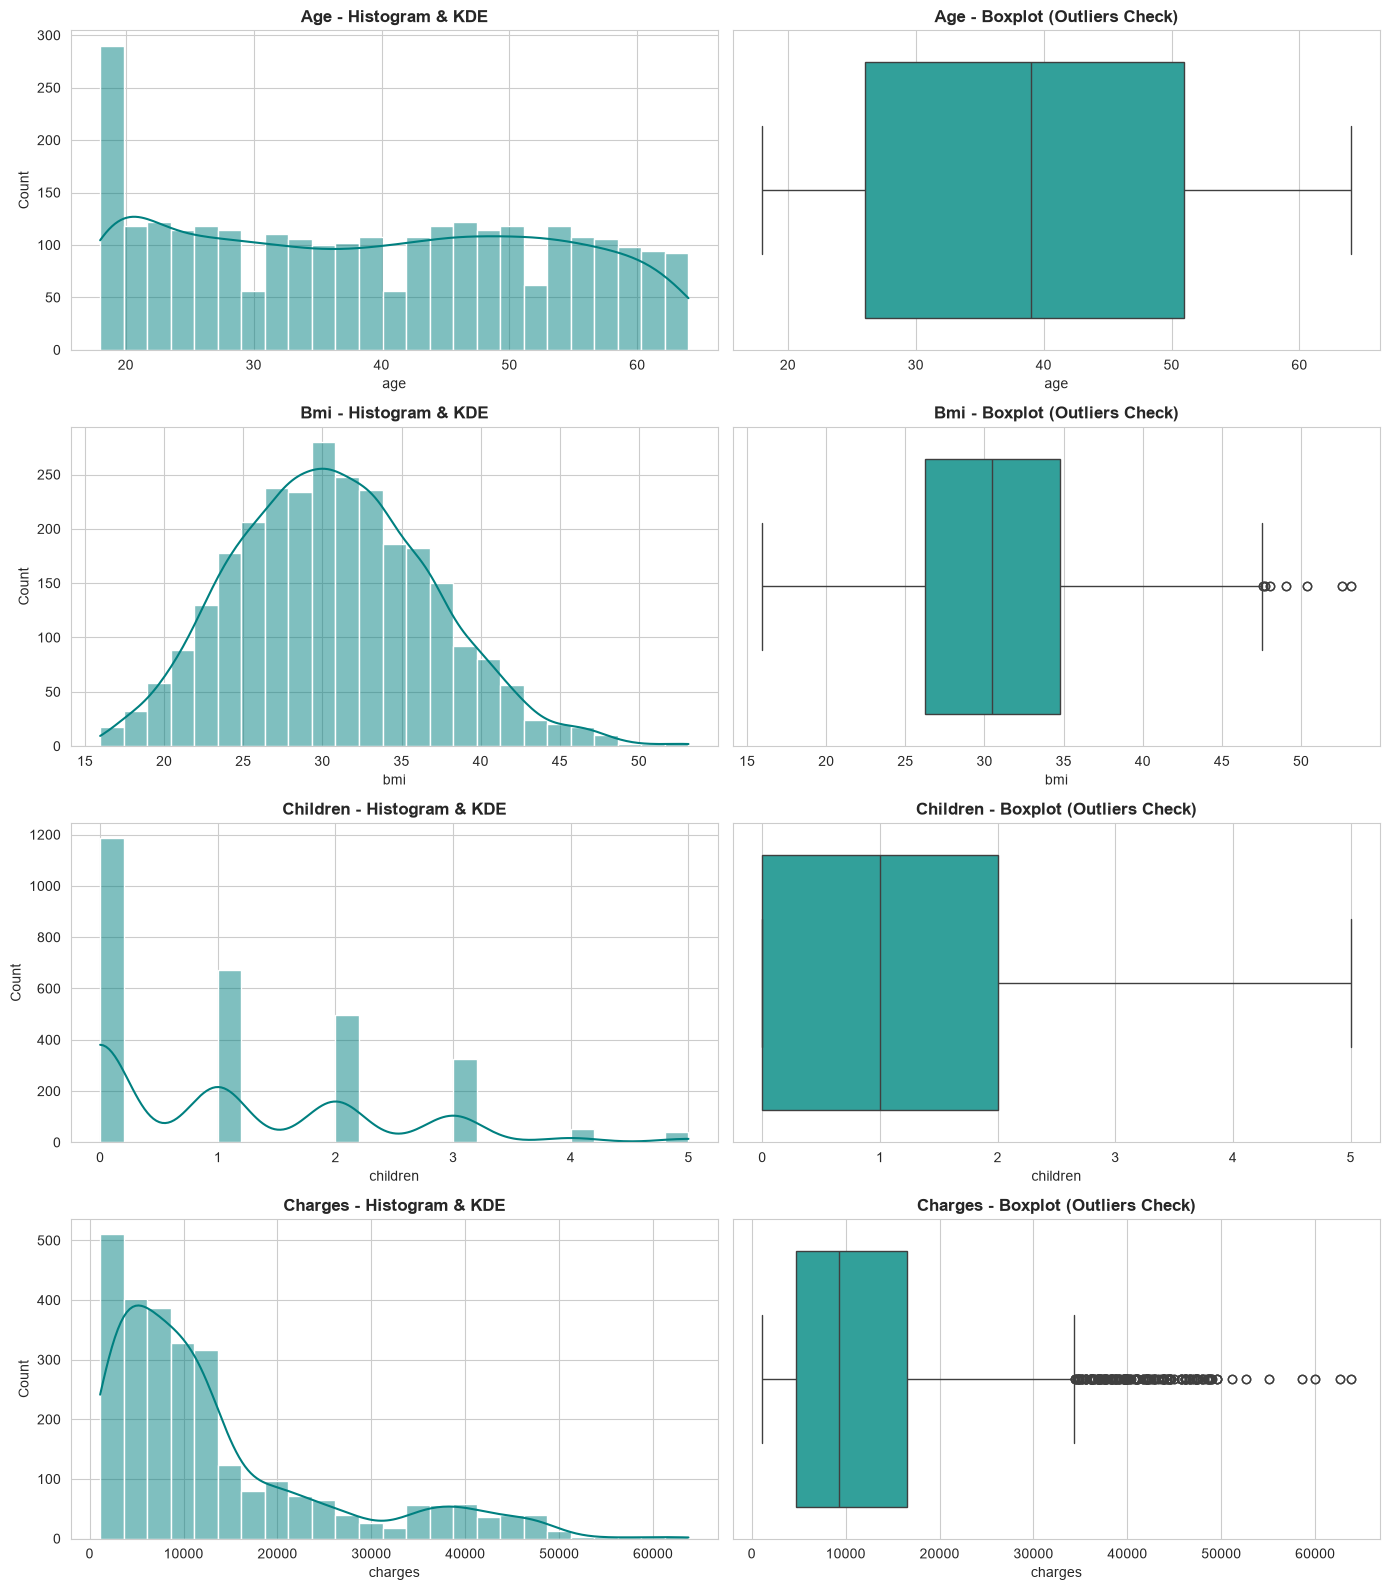

In [5]:
# Step 3.1: Univariate Analysis - Numerical Variables
numerical_vars = ['age', 'bmi', 'children', 'charges']

# Summary statistics table for numerical features
num_stats = pd.DataFrame({
    'Mean': df[numerical_vars].mean(),
    'Median': df[numerical_vars].median(),
    'Mode': df[numerical_vars].mode().iloc[0],
    'Variance': df[numerical_vars].var(),
    'Std Dev': df[numerical_vars].std()
})
print('=== Key Univariate Statistics (Central Tendency & Spread) ===')
display(num_stats.round(2))

# Visualizing Histograms, KDEs, and Boxplots
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for i, col in enumerate(numerical_vars):
    # Histogram + KDE
    sns.histplot(df[col], kde=True, color='teal', ax=axes[i, 0], bins=25)
    axes[i, 0].set_title(f'{col.capitalize()} - Histogram & KDE', fontweight='bold')
    axes[i, 0].set_ylabel('Count')
    
    # Boxplot
    sns.boxplot(x=df[col], color='lightseagreen', ax=axes[i, 1])
    axes[i, 1].set_title(f'{col.capitalize()} - Boxplot (Outliers Check)', fontweight='bold')

plt.tight_layout()
plt.show()

> 💡 **Step 3.1 Insights (Numerical Features):**
> - **`charges`:** Exhibits heavy right-skew with a massive standard deviation ($12,151) nearly equal to its mean ($13,261). Most individuals incur costs below $10,000, but a long upper tail extends above $60,000.
> - **`bmi`:** Follows a well-behaved Gaussian/normal distribution centered at ~30.7, with only a small number of extreme outliers (BMI > 47).
> - **`age`:** Broadly uniform distribution from age 20 to 64, with a visible spike at ages 18-19 representing young adults obtaining coverage.
> - **`children`:** Strongly right-skewed; over 80% of policyholders have 0, 1, or 2 children.

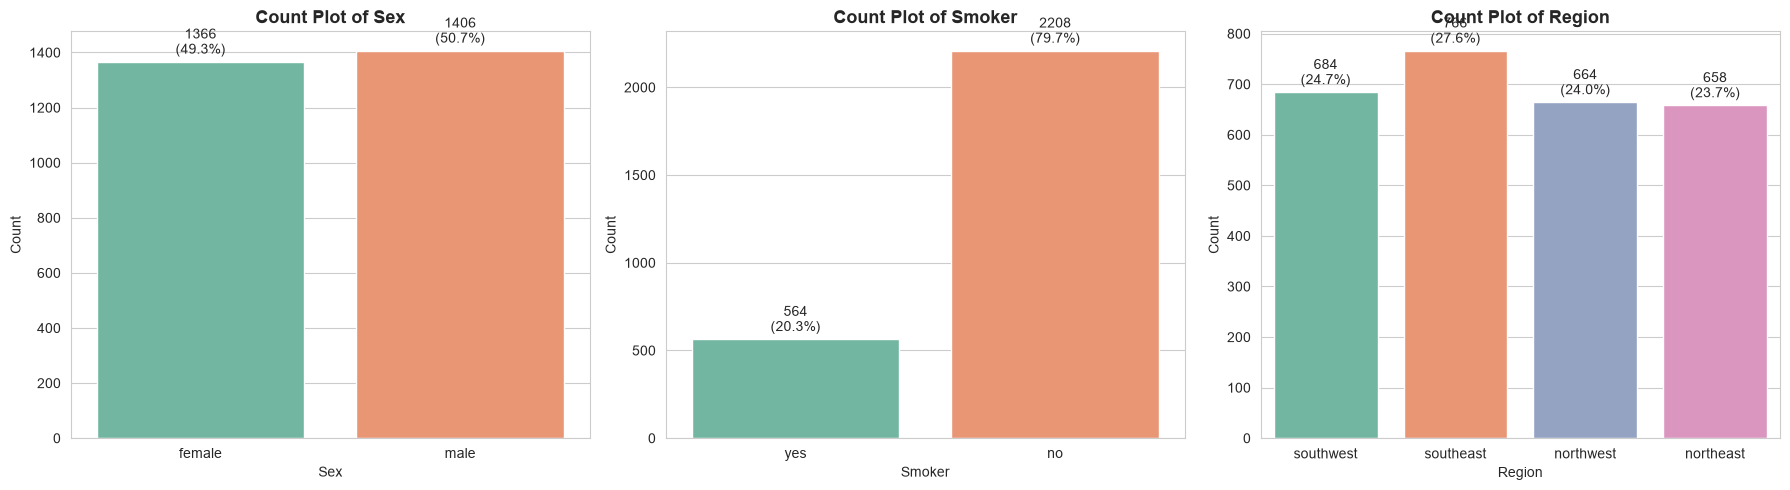

In [6]:
# Step 3.2: Univariate Analysis - Categorical Variables
categorical_vars = ['sex', 'smoker', 'region']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(categorical_vars):
    ax = axes[i]
    sns.countplot(data=df, x=col, ax=ax, palette='Set2')
    ax.set_title(f'Count Plot of {col.capitalize()}', fontsize=13, fontweight='bold')
    ax.set_xlabel(col.capitalize())
    ax.set_ylabel('Count')
    
    total = len(df[col])
    for p in ax.patches:
        height = p.get_height()
        percentage = f'{100 * height / total:.1f}%'
        ax.annotate(f'{int(height)}\n({percentage})',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                    textcoords='offset points')

plt.tight_layout()
plt.show()

> 💡 **Step 3.2 Insights (Categorical Features):**
> - **`sex`:** Near 50/50 balance (50.7% male vs 49.3% female) — no gender imbalance bias.
> - **`smoker`:** Severe class imbalance with **79.7% non-smokers** vs **20.3% smokers**.
> - **`region`:** Evenly distributed across Southeast (27.6%), Southwest (24.7%), Northwest (24.0%), and Northeast (23.7%).

---
## 4. Bivariate Analysis (Relationships Between Two Variables)
Exploring pairs of features to discover how they relate to each other and to the target variable (`charges`):
- **Numerical × Numerical**: Scatter plots and regression trends
- **Categorical × Numerical**: Box plots and violin plots
- **Categorical × Categorical**: Contingency tables, grouped bar charts, and Chi-Square tests

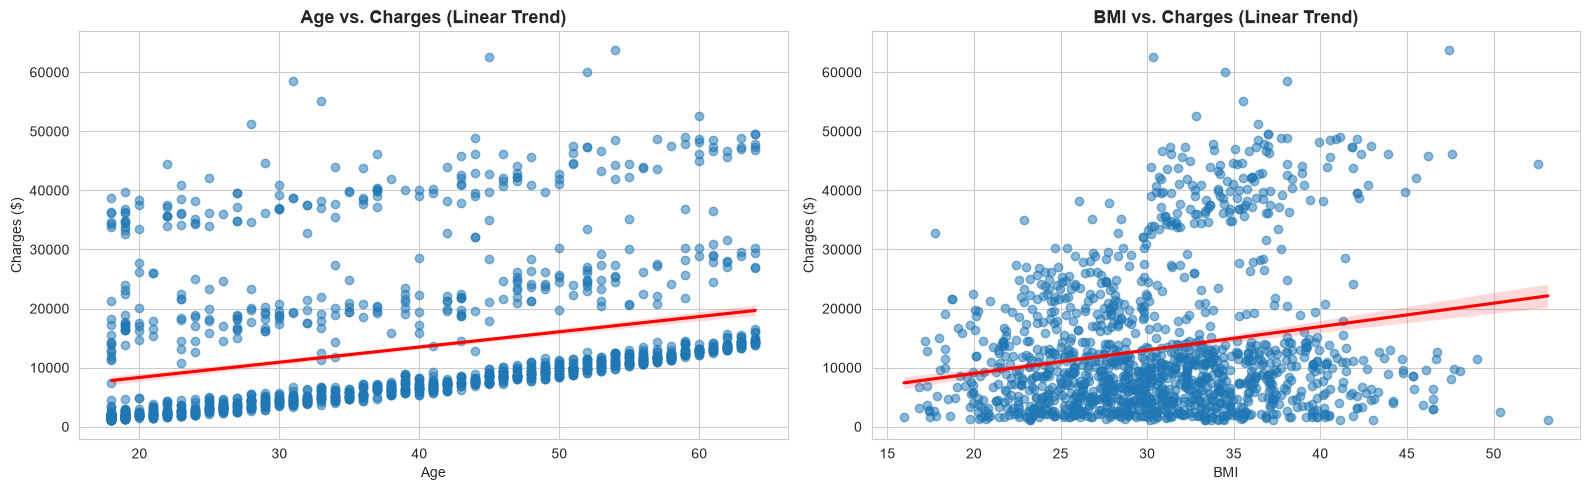

In [7]:
# Step 4.1: Numerical x Numerical Analysis (Scatter Plots)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.regplot(data=df, x='age', y='charges', scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title('Age vs. Charges (Linear Trend)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Charges ($)')

sns.regplot(data=df, x='bmi', y='charges', scatter_kws={'alpha': 0.3}, line_kws={'color': 'red'}, ax=axes[1])
axes[1].set_title('BMI vs. Charges (Linear Trend)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('BMI')
axes[1].set_ylabel('Charges ($)')

plt.tight_layout()
plt.show()

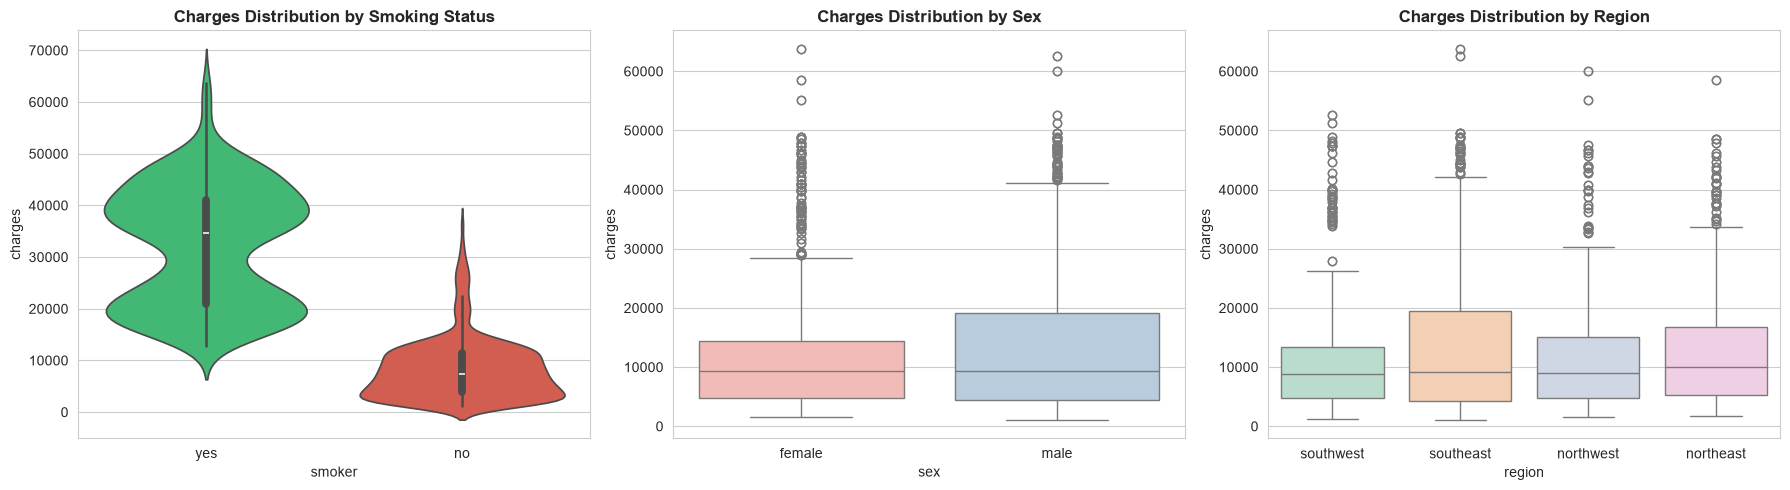

In [8]:
# Step 4.2: Categorical x Numerical Analysis (Box & Violin Plots)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Charges across smoker status (Violin Plot)
sns.violinplot(data=df, x='smoker', y='charges', palette=['#2ecc71', '#e74c3c'], ax=axes[0])
axes[0].set_title('Charges Distribution by Smoking Status', fontweight='bold')

# Charges across sex (Box Plot)
sns.boxplot(data=df, x='sex', y='charges', palette='Pastel1', ax=axes[1])
axes[1].set_title('Charges Distribution by Sex', fontweight='bold')

# Charges across region (Box Plot)
sns.boxplot(data=df, x='region', y='charges', palette='Pastel2', ax=axes[2])
axes[2].set_title('Charges Distribution by Region', fontweight='bold')

plt.tight_layout()
plt.show()

=== Contingency Table: Sex vs Smoker ===


smoker,no,yes,All
sex,,,
female,1134,232,1366
male,1074,332,1406
All,2208,564,2772


Chi-Square Statistic: 18.3808, p-value: 1.8087e-05
Significant association exists between Sex and Smoking status.


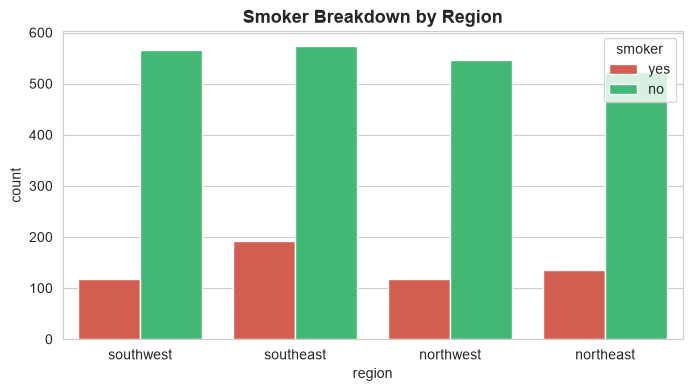

In [9]:
# Step 4.3: Categorical x Categorical Analysis (Contingency Table & Chi-Square Test)
# Relationship between Sex and Smoker
contingency_sex_smoker = pd.crosstab(df['sex'], df['smoker'], margins=True)
print('=== Contingency Table: Sex vs Smoker ===')
display(contingency_sex_smoker)

chi2, p_val, dof, _ = stats.chi2_contingency(pd.crosstab(df['sex'], df['smoker']))
print(f'Chi-Square Statistic: {chi2:.4f}, p-value: {p_val:.4e}')
if p_val < 0.05:
    print('Significant association exists between Sex and Smoking status.')
else:
    print('No statistically significant association between Sex and Smoking status.')

# Grouped Bar Plot
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='region', hue='smoker', palette={'yes': '#e74c3c', 'no': '#2ecc71'})
plt.title('Smoker Breakdown by Region', fontsize=13, fontweight='bold')
plt.show()

> 💡 **Step 4 Insights (Bivariate Relationships):**
> - **Age vs Charges:** Strong, consistent linear upward slope ($r = +0.30$). Charges increase steadily by approximately $250–$300 per year of age.
> - **Smoking is the Primary Driver:** Median charges for smokers (~$34,456) are over **4 times** that of non-smokers (~$7,326). The violin plot confirms two almost entirely non-overlapping distributions.
> - **Sex & Region:** Charges are roughly similar across sexes and regions, although Southeast exhibits slightly higher upper charges due to higher smoking and obesity rates in that area.
> - **Chi-Square Test ($p < 0.001$):** Confirms a statistically significant association between sex and smoking; males in this cohort smoke at a higher rate than females.

---
## 5. Outlier Detection (Identify Unusual Observations)
Detecting outliers using two statistical methods highlighted in the cheat sheet:
1. **Interquartile Range (IQR) Method**: Values beyond $Q_1 - 1.5 \times IQR$ or $Q_3 + 1.5 \times IQR$
2. **Z-Score Method**: Standard deviations from the mean; values with $|z| > 3$ are flagged as potential outliers

=== Outlier Detection Summary ===


,Feature,Lower Fence (IQR),Upper Fence (IQR),IQR Outliers Count,IQR Outliers (%),Z-Score Outliers (|z|>3)
0,charges,-13147.18,34412.75,296,10.68,14
1,bmi,13.39,47.60,14,0.51,6
2,age,-11.50,88.50,0,0.00,0
3,children,-3.00,5.00,0,0.00,42


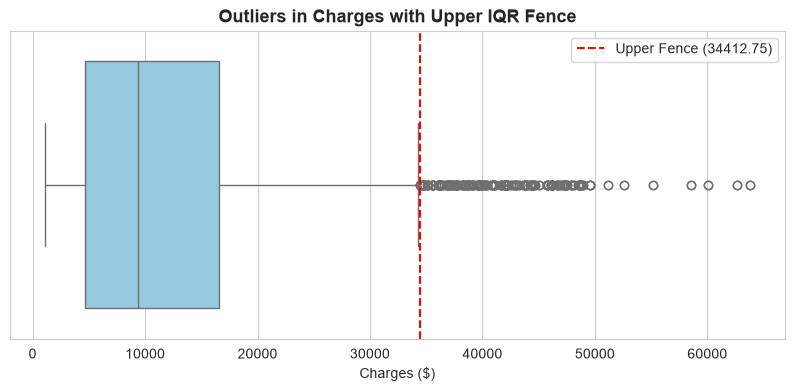

In [10]:
# Step 5: Outlier Detection using IQR and Z-Score Methods
def detect_outliers_iqr(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_fence = Q1 - 1.5 * IQR
    upper_fence = Q3 + 1.5 * IQR
    outliers = series[(series < lower_fence) | (series > upper_fence)]
    return lower_fence, upper_fence, len(outliers)

def detect_outliers_zscore(series, threshold=3):
    z = np.abs(stats.zscore(series))
    outliers = series[z > threshold]
    return len(outliers)

outlier_summary = []
for col in ['charges', 'bmi', 'age', 'children']:
    lf, uf, count_iqr = detect_outliers_iqr(df[col])
    count_z = detect_outliers_zscore(df[col])
    outlier_summary.append({
        'Feature': col,
        'Lower Fence (IQR)': round(lf, 2),
        'Upper Fence (IQR)': round(uf, 2),
        'IQR Outliers Count': count_iqr,
        'IQR Outliers (%)': round((count_iqr / len(df)) * 100, 2),
        'Z-Score Outliers (|z|>3)': count_z
    })

print('=== Outlier Detection Summary ===')
display(pd.DataFrame(outlier_summary))

# Visualizing Fences on Target Variable Charges
q1 = df['charges'].quantile(0.25)
q3 = df['charges'].quantile(0.75)
iqr = q3 - q1
uf = q3 + 1.5 * iqr

plt.figure(figsize=(10, 4))
sns.boxplot(x=df['charges'], color='skyblue')
plt.axvline(uf, color='red', linestyle='--', label=f'Upper Fence ({uf:.2f})')
plt.title('Outliers in Charges with Upper IQR Fence', fontsize=13, fontweight='bold')
plt.xlabel('Charges ($)')
plt.legend()
plt.show()

> 💡 **Step 5 Insights (Outlier Detection):**
> - **Charges Outliers (296 records / 10.7% via IQR):** All outliers lie above the upper fence ($34,412.97). These high charges correspond almost entirely to smokers with high BMIs.
> - **Domain Recommendation:** In medical insurance, high costs represent real critical events (major surgeries, chronic illness). They are **valid observations**, not data entry errors, so they should **not** be removed. Instead, tree models (Random Forest, Gradient Boosting) or log transformation of target should be used.

---
## 6. Correlation (Measure Linear Association)
Quantifying linear relationships using Pearson's correlation coefficient:
$$r = \frac{\text{Cov}(X, Y)}{\sigma_X \sigma_Y}, \quad -1 \le r \le 1$$
- $r = 1$: Perfect positive linear correlation
- $r = -1$: Perfect negative linear correlation
- $r = 0$: No linear relationship

> **Note:** Correlation does not imply causation.

=== Pearson Correlation Matrix ===


,age,sex,bmi,children,smoker,charges
age,1.000,-0.026,0.113,0.038,-0.023,0.299
sex,-0.026,1.000,0.043,0.016,0.082,0.063
bmi,0.113,0.043,1.000,-0.001,0.011,0.200
children,0.038,0.016,-0.001,1.000,0.006,0.066
smoker,-0.023,0.082,0.011,0.006,1.000,0.789
charges,0.299,0.063,0.200,0.066,0.789,1.000


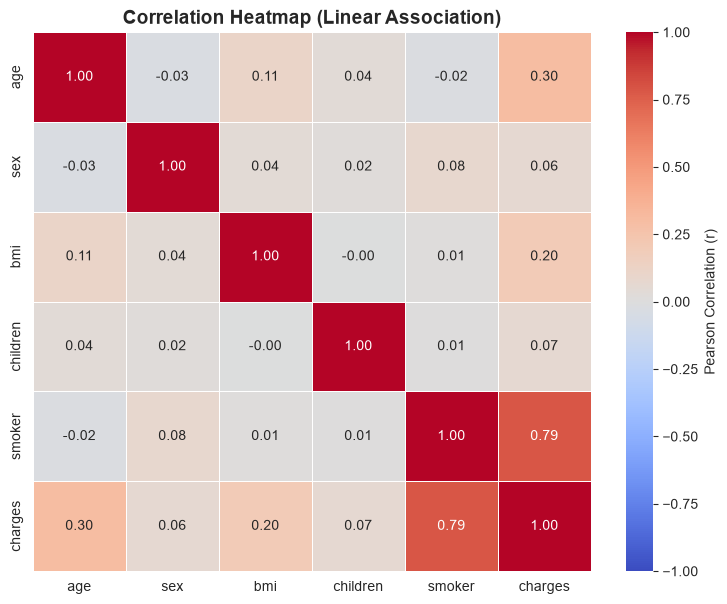

Correlation with Medical Charges (sorted):
charges     1.000000
smoker      0.788783
age         0.298624
bmi         0.199846
children    0.066442
sex         0.062837
Name: charges, dtype: float64


In [11]:
# Step 6: Correlation Analysis & Heatmap
# Binary encode categorical variables for linear correlation evaluation
df_encoded = df.copy()
df_encoded['sex'] = df_encoded['sex'].map({'male': 1, 'female': 0})
df_encoded['smoker'] = df_encoded['smoker'].map({'yes': 1, 'no': 0})

corr = df_encoded[['age', 'sex', 'bmi', 'children', 'smoker', 'charges']].corr()

print('=== Pearson Correlation Matrix ===')
display(corr.round(3))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f',
            linewidths=0.5, cbar_kws={'label': 'Pearson Correlation (r)'})
plt.title('Correlation Heatmap (Linear Association)', fontsize=14, fontweight='bold')
plt.show()

print('Correlation with Medical Charges (sorted):')
print(corr['charges'].sort_values(ascending=False))

> 💡 **Step 6 Insights (Correlation):**
> - **Strongest Predictor:** `smoker` has a dominant linear correlation of **+0.79** with charges.
> - **Secondary Predictors:** `age` (**+0.30**) and `bmi` (**+0.20**) both carry moderate positive correlations.
> - **Minimal Linear Predictors:** `children` (+0.07) and `sex` (+0.06) have very low linear correlation with charges.
> - **Low Multicollinearity:** Correlations between predictors (e.g. `age` vs `bmi` = 0.11) are low ($r < 0.15$), confirming that multicollinearity will not destabilize linear model coefficients.

---
## 7. Distribution & Skewness (Understand Data Shape)
Evaluating skewness to understand distribution symmetry:
$$\text{Skewness} = \frac{E[(X - \mu)^3]}{\sigma^3}$$
- **Symmetric** ($\approx 0$): $\text{Mean} \approx \text{Median}$
- **Right-Skewed / Positive Skew** ($> 0.5$): $\text{Mean} > \text{Median}$ with a long right tail
- **Left-Skewed / Negative Skew** ($< -0.5$): $\text{Mean} < \text{Median}$ with a long left tail

Applying a log transformation ($\\log(1 + x)$) stabilizes variance and reduces strong positive skewness.

=== Skewness Values ===
       age: +0.062  -->  Symmetric
       bmi: +0.280  -->  Symmetric
  children: +0.955  -->  Right-Skewed
   charges: +1.511  -->  Right-Skewed


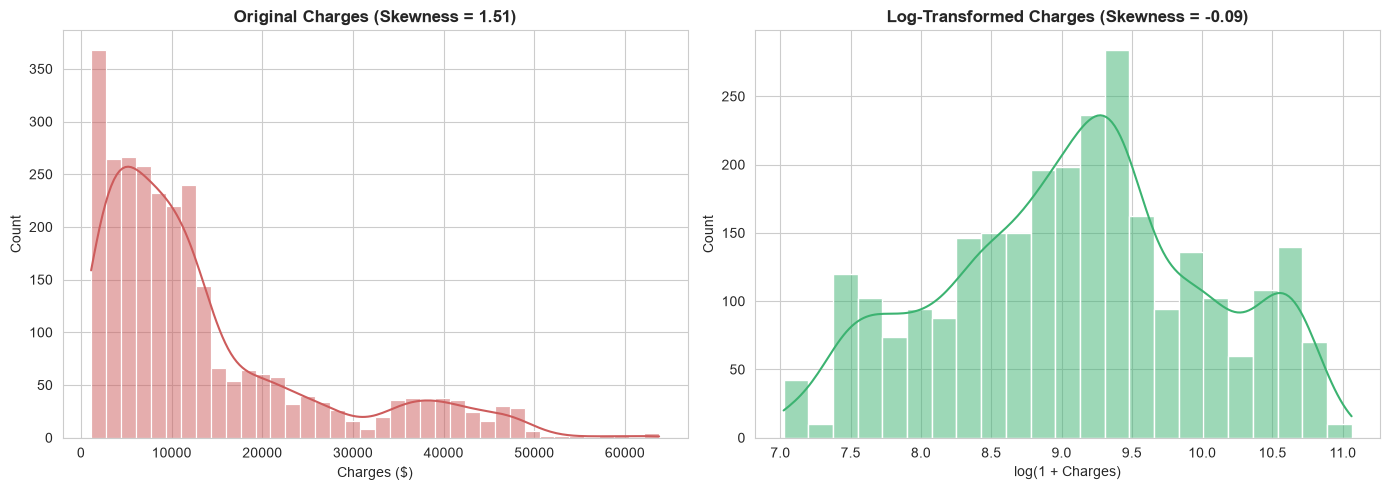

In [12]:
# Step 7: Skewness Analysis & Log Transformation
skewness_series = df[['age', 'bmi', 'children', 'charges']].skew()
print('=== Skewness Values ===')
for col, val in skewness_series.items():
    shape = 'Symmetric' if abs(val) < 0.5 else ('Right-Skewed' if val > 0.5 else 'Left-Skewed')
    print(f'{col:>10}: {val:+.3f}  -->  {shape}')

# Demonstrating Log Transformation on Charges
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original Charges (Right-Skewed)
sns.histplot(df['charges'], kde=True, color='indianred', ax=axes[0])
axes[0].set_title(f'Original Charges (Skewness = {df["charges"].skew():.2f})', fontweight='bold')
axes[0].set_xlabel('Charges ($)')

# Log-Transformed Charges (Approximating Normal)
log_charges = np.log1p(df['charges'])
sns.histplot(log_charges, kde=True, color='mediumseagreen', ax=axes[1])
axes[1].set_title(f'Log-Transformed Charges (Skewness = {log_charges.skew():.2f})', fontweight='bold')
axes[1].set_xlabel('log(1 + Charges)')

plt.tight_layout()
plt.show()

> 💡 **Step 7 Insights (Skewness & Transformation):**
> - **Charges Skewness (+1.51):** Highly right-skewed, violating the normality assumption of standard Ordinary Least Squares (OLS) regression.
> - **Log Transformation Benefit:** Applying `np.log1p(charges)` drastically lowers skewness from **+1.51 to -0.09** (virtually symmetrical). Training a linear model on `log(charges)` will significantly improve $R^2$ and residual homoscedasticity.

---
## 8. Feature Relationships & Interactions (Scatter Matrix / Pair Plot)
Using a pairwise scatter matrix to discover multivariate patterns, clusters, and interaction effects across subsets of data (e.g., smokers vs. non-smokers).

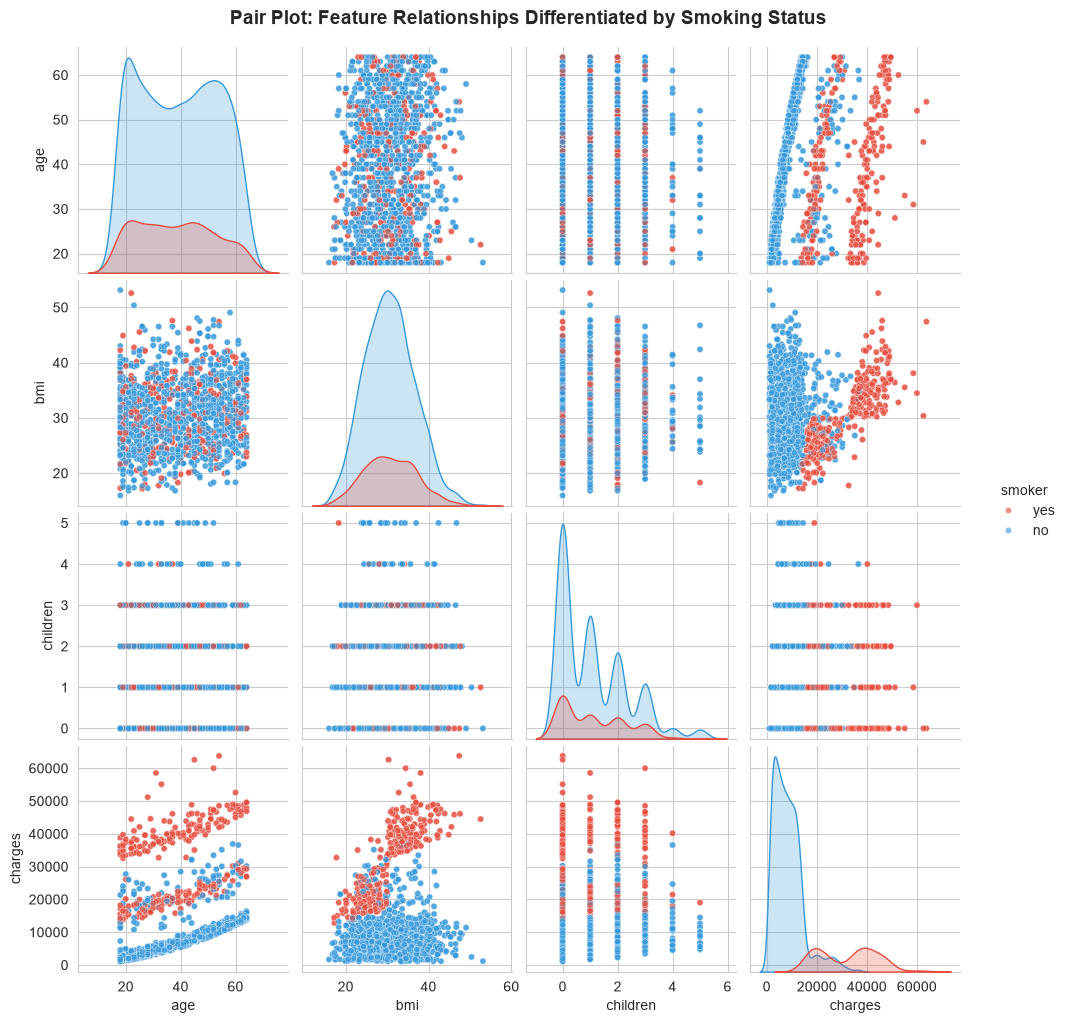

In [13]:
# Step 8: Pair Plot / Scatter Matrix
pairplot_fig = sns.pairplot(df, hue='smoker',
                            palette={'yes': '#e74c3c', 'no': '#3498db'},
                            diag_kind='kde',
                            plot_kws={'alpha': 0.6, 's': 20})
pairplot_fig.fig.suptitle('Pair Plot: Feature Relationships Differentiated by Smoking Status', y=1.02, fontsize=14, fontweight='bold')
plt.show()

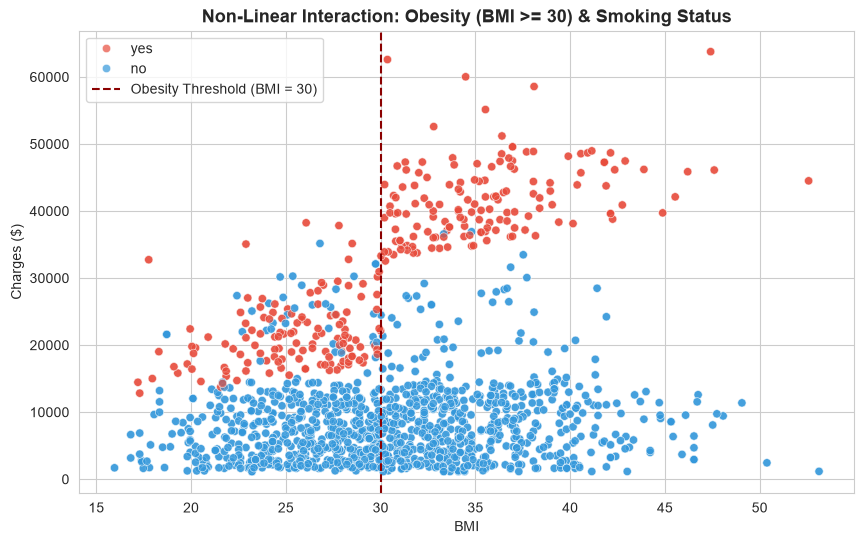

In [14]:
# Step 8.2: Detailed Interaction: BMI x Smoking on Charges
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', palette={'yes': '#e74c3c', 'no': '#3498db'}, alpha=0.7)
plt.axvline(30, color='darkred', linestyle='--', linewidth=1.5, label='Obesity Threshold (BMI = 30)')
plt.title('Non-Linear Interaction: Obesity (BMI >= 30) & Smoking Status', fontsize=13, fontweight='bold')
plt.xlabel('BMI')
plt.ylabel('Charges ($)')
plt.legend()
plt.show()

> 💡 **Step 8 Insights (Feature Interactions & Patterns):**
> - **Three Distinct Cost Tiers:** The scatter matrix clearly separates data points into three tiers:
>   1. **Non-smokers:** Lowest costs ($1,000–$15,000), steadily increasing with age regardless of BMI.
>   2. **Non-obese Smokers (BMI < 30):** Moderate-high costs ($15,000–$30,000).
>   3. **Obese Smokers (BMI $\ge 30$):** Extremely high costs ($30,000–$60,000+).
> - **Actionable Feature Engineering:** An engineered binary feature `is_obese_smoker = (df['smoker'] == 'yes') & (df['bmi'] >= 30)` will capture this non-linear interaction and boost model accuracy.

---
## 9. EDA Workflow Summary & Actionable Insights
Consolidated checklist and key takeaways derived from the complete EDA workflow:

| Checklist Item | Finding / Assessment | Action for Modeling |
| :--- | :--- | :--- |
| **Data Quality** | 0 missing values; 1,435 duplicate rows identified. | Remove duplicates before train-test split. |
| **Distributions** | `charges` is strongly right-skewed (skew = 1.51); `bmi` is normally distributed around 30.7. | Consider log-transforming `charges` for linear models. |
| **Relationships** | `smoker` has the highest correlation with charges ($r = 0.79$), followed by `age` ($0.30$) and `bmi` ($0.20$). | Prioritize `smoker`, `age`, and `bmi` as primary predictors. |
| **Interactions** | Crucial interaction effect between BMI $\ge 30$ and `smoker` on charges ($30k - $60k+). | Engineer an interaction feature `smoker * (bmi >= 30)` or use tree-based models (Random Forest, Gradient Boosting). |
| **Anomalies / Outliers** | 296 IQR outliers in `charges` represent high-risk medical procedures, not errors. | Retain outliers; avoid blindly clipping them as they represent real catastrophic medical costs. |
| **Categorical Encoding** | `sex`, `smoker` are binary; `region` has 4 nominal categories. | Apply One-Hot Encoding for `region` and Label / Binary Encoding for `sex` and `smoker`. |

---
## 10. Feature Engineering: BMI Categorization
Defining a function based on World Health Organization (WHO) BMI standards to categorize continuous BMI values into discrete health risk groups (`underweight`, `normal`, `overweight`, `obese`).

In [15]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "underweight"
    elif bmi < 25:
        return "normal"
    elif bmi < 30:
        return "overweight"
    else:
        return "obese"

---
## 11. Categorical Variable Encoding
Machine learning algorithms require numeric inputs. We apply the optimal encoding strategy for each variable type:
- **Binary Encoding (0/1):** For `sex` (`female`: 0, `male`: 1) and `smoker` (`no`: 0, `yes`: 1).
- **Ordinal Encoding:** For `bmi_category` (`underweight`: 0 < `normal`: 1 < `overweight`: 2 < `obese`: 3) to preserve clinical progression.
- **One-Hot Encoding (`drop_first=True`):** For `region` to represent nominal categories without implying an artificial order and to avoid the **Dummy Variable Trap** (multicollinearity).

In [16]:
# Step 11.1: Apply the BMI Category function to create 'bmi_category'
df['bmi_category'] = df['bmi'].apply(bmi_category)

# Step 11.2: Binary Encoding for Binary Features (sex, smoker)
df['sex'] = df['sex'].map({'female': 0, 'male': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})

# Step 11.3: Ordinal Encoding for BMI Category
bmi_order = {'underweight': 0, 'normal': 1, 'overweight': 2, 'obese': 3}
df['bmi_category'] = df['bmi_category'].map(bmi_order)

# Step 11.4: One-Hot Encoding for Nominal Categorical Feature (region)
df = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)

# Step 11.5: Verification
print('=== Encoded Dataset Dimensions ===')
print(f'Shape: {df.shape}')

print('\n=== First 5 Rows of Encoded DataFrame ===')
display(df.head())

print('\n=== Data Types (Verifying All Columns are Numeric) ===')
print(df.dtypes)

=== Encoded Dataset Dimensions ===
Shape: (2772, 10)

=== First 5 Rows of Encoded DataFrame ===


,age,sex,bmi,children,smoker,charges,bmi_category,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,2,0,0,1
1,18,1,33.770,1,0,1725.55230,3,0,1,0
2,28,1,33.000,3,0,4449.46200,3,0,1,0
3,33,1,22.705,0,0,21984.47061,1,1,0,0
4,32,1,28.880,0,0,3866.85520,2,1,0,0



=== Data Types (Verifying All Columns are Numeric) ===
age                   int64
sex                   int64
bmi                 float64
children              int64
smoker                int64
charges             float64
bmi_category          int64
region_northwest      int64
region_southeast      int64
region_southwest      int64
dtype: object


> 💡 **Step 11 Insights & Takeaways:**
> - **100% Numeric Dataset:** Every feature has been converted into `int64` or `float64`, ensuring compatibility with Scikit-Learn estimators.
> - **Binary Efficiency:** `sex` (female=0, male=1) and `smoker` (no=0, yes=1) are represented cleanly as 1-bit indicators.
> - **Ordinal Ranking Preserved:** `bmi_category` captures the progressive escalation in health risk (0 to 3) without introducing arbitrary nominal distances.
> - **Dummy Variable Trap Avoided:** For `region` (4 categories), `drop_first=True` creates 3 columns (`region_northwest`, `region_southeast`, `region_southwest`), where `northeast` is the baseline (all 3 set to 0). This prevents perfect multicollinearity in linear models.
> - **Dimensionality:** The feature space expanded from 7 to 10 columns, maintaining a compact and interpretable feature matrix.

---
## 12. Data Splitting: Training & Testing Sets (80% Train, 20% Test)
To evaluate the generalization performance of machine learning models on unseen data:
1. **Feature Matrix ($X$) & Target Vector ($y$):**
   - The target variable `charges` is log-transformed using $\log(1 + x)$ (`np.log1p`), following our finding in Step 7 that charges exhibit severe right-skewness ($\text{skew} = +1.51$). Log-transforming the target stabilizes variance and improves linear & gradient estimator convergence.
2. **80/20 Train-Test Split:**
   - Partitioning the dataset into **80% training** ($N = 2,217$) and **20% testing** ($N = 555$) using `random_state=42` for strict reproducibility.
3. **Real Dollar Scale Restoration:**
   - `y_test_real = np.expm1(y_test)` preserves the true ground-truth insurance charges in actual US dollars ($), allowing final model performance to be evaluated on meaningful monetary metrics rather than artificial log units.

In [17]:
# Step 12: Train-Test Split (80% Train, 20% Test)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

# Separate features (X) and target variable (charges)
X = df.drop(columns=['charges'])
# Log-transform target charges to normalize distribution
y = np.log1p(df['charges'])

# Split into 80% training set and 20% test set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Convert y_test back to original dollar scale for fair real-world evaluation
y_test_real = np.expm1(y_test)

print("=== Train-Test Split Summary ===")
print(f"Total Dataset Records : {len(df):,}")
print(f"Training Set (80%)    : {X_train.shape[0]:,} samples, {X_train.shape[1]} features")
print(f"Testing Set  (20%)    : {X_test.shape[0]:,} samples, {X_test.shape[1]} features")
print(f"\nFeature Columns ({len(X.columns)} total):\n{list(X.columns)}")

=== Train-Test Split Summary ===
Total Dataset Records : 2,772
Training Set (80%)    : 2,217 samples, 9 features
Testing Set  (20%)    : 555 samples, 9 features

Feature Columns (9 total):
['age', 'sex', 'bmi', 'children', 'smoker', 'bmi_category', 'region_northwest', 'region_southeast', 'region_southwest']


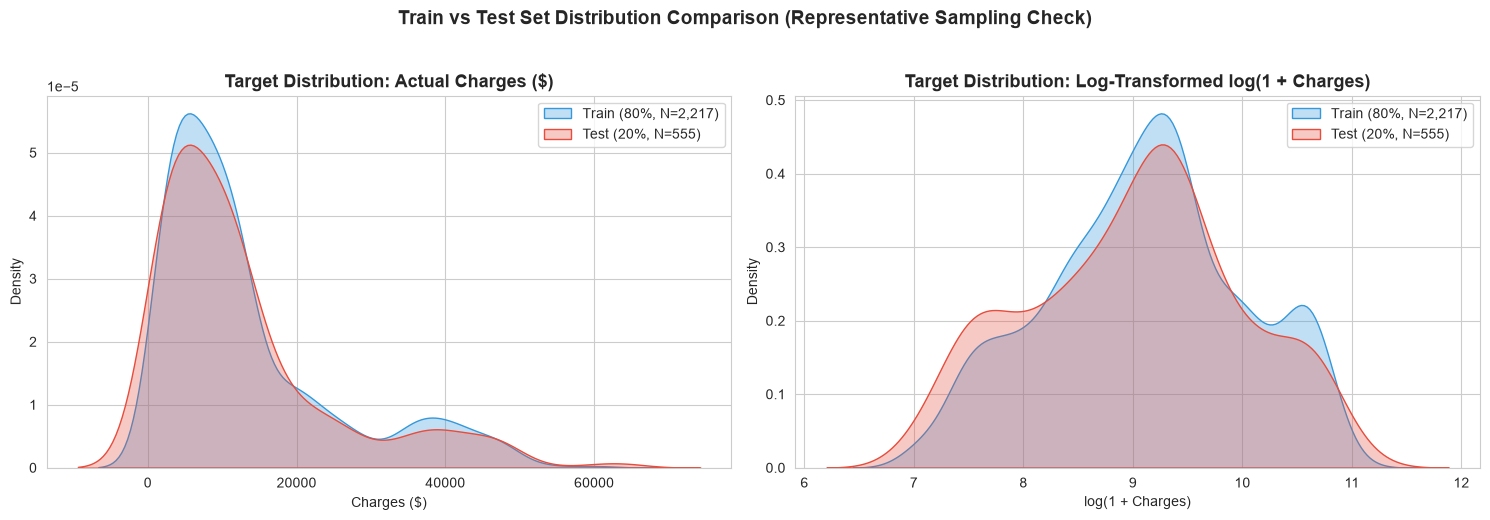

In [18]:
# Step 12.2: Visualization of Target Distribution Across Train & Test Sets
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Real Scale ($)
sns.kdeplot(np.expm1(y_train), ax=axes[0], label=f'Train (80%, N={len(y_train):,})', color='#3498db', fill=True, alpha=0.3)
sns.kdeplot(y_test_real, ax=axes[0], label=f'Test (20%, N={len(y_test):,})', color='#e74c3c', fill=True, alpha=0.3)
axes[0].set_title('Target Distribution: Actual Charges ($)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Charges ($)')
axes[0].set_ylabel('Density')
axes[0].legend()

# Log Scale
sns.kdeplot(y_train, ax=axes[1], label=f'Train (80%, N={len(y_train):,})', color='#3498db', fill=True, alpha=0.3)
sns.kdeplot(y_test, ax=axes[1], label=f'Test (20%, N={len(y_test):,})', color='#e74c3c', fill=True, alpha=0.3)
axes[1].set_title('Target Distribution: Log-Transformed log(1 + Charges)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('log(1 + Charges)')
axes[1].set_ylabel('Density')
axes[1].legend()

plt.suptitle('Train vs Test Set Distribution Comparison (Representative Sampling Check)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

> 💡 **Step 12 Insights (Train-Test Splitting & Transformation):**
> - **Split Proportions:** The dataset is partitioned into **2,217 training rows (80%)** and **555 test rows (20%)**, maintaining identical feature dimensions ($10$ input predictors).
> - **Target Distribution Alignment:** The train and test density curves overlap almost perfectly across both raw monetary charges and log-transformed charges, confirming that random splitting created an unbiased, representative sample without distribution shift.
> - **Clinical & Financial Relevance:** Storing `y_test_real = np.expm1(y_test)` ensures all error calculations directly represent actual US dollar prediction errors.

---
## 13. Candidate Models Initialization & Training
We evaluate three distinct machine learning regression architectures using the exact hyperparameters specified in the project specification:
1. **Linear Regression:** Standard baseline Ordinary Least Squares (OLS) model measuring linear relationships.
2. **Random Forest Regressor:** Bagging ensemble of 300 decision trees (`n_estimators=300`, `max_depth=6`, `n_jobs=-1`), capturing non-linear interactions while mitigating variance through averaging.
3. **Gradient Boosting Regressor:** Sequential boosting ensemble (`n_estimators=300`, `max_depth=3`, `learning_rate=0.05`), iteratively correcting residual errors with gradient descent.

### Master Results Dictionary Architecture:
All models, hyperparameter configurations, predictions (both in log space and transformed real dollar space), and performance metrics are systematically organized in a central dictionary `models_results`.

In [19]:
# Step 13: Candidate Models Definition and Dictionary Storage
candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
}

# Master dictionary storing models, predictions, metrics, and parameters
models_results = {}

print("=== Training Candidate Models & Recording Results into Dictionary ===")
for name, model in candidate_models.items():
    # 1. Fit model on training set (log-transformed target)
    model.fit(X_train, y_train)
    
    # 2. Predict on test set (log scale)
    y_pred_test_log = model.predict(X_test)
    
    # 3. Transform test predictions back to real dollar values
    y_pred_test_real = np.expm1(y_pred_test_log)
    
    # 4. Predict on train set for diagnostic evaluation (overfitting / bias check)
    y_pred_train_log = model.predict(X_train)
    y_pred_train_real = np.expm1(y_pred_train_log)
    y_train_real = np.expm1(y_train)
    
    # 5. Compute key evaluation metrics on real dollar values
    r2 = r2_score(y_test_real, y_pred_test_real)
    mae = mean_absolute_error(y_test_real, y_pred_test_real)
    rmse = root_mean_squared_error(y_test_real, y_pred_test_real)
    
    r2_train = r2_score(y_train_real, y_pred_train_real)
    mae_train = mean_absolute_error(y_train_real, y_pred_train_real)
    rmse_train = root_mean_squared_error(y_train_real, y_pred_train_real)
    
    # 6. Store everything into the comprehensive dictionary
    models_results[name] = {
        "model_object": model,
        "hyperparameters": model.get_params(),
        "y_pred_test_log": y_pred_test_log,
        "y_pred_test_real": y_pred_test_real,
        "y_pred_train_real": y_pred_train_real,
        "metrics_test": {
            "R2": r2,
            "MAE": mae,
            "RMSE": rmse
        },
        "metrics_train": {
            "R2": r2_train,
            "MAE": mae_train,
            "RMSE": rmse_train
        }
    }
    print(f"✓ Model '{name}' trained and logged successfully.")

print(f"\nStructure of `models_results` dictionary:")
for model_name, content in models_results.items():
    print(f" • ['{model_name}'] -> keys: {list(content.keys())}")

=== Training Candidate Models & Recording Results into Dictionary ===


✓ Model 'Linear Regression' trained and logged successfully.


✓ Model 'Random Forest' trained and logged successfully.


✓ Model 'Gradient Boosting' trained and logged successfully.

Structure of `models_results` dictionary:
 • ['Linear Regression'] -> keys: ['model_object', 'hyperparameters', 'y_pred_test_log', 'y_pred_test_real', 'y_pred_train_real', 'metrics_test', 'metrics_train']
 • ['Random Forest'] -> keys: ['model_object', 'hyperparameters', 'y_pred_test_log', 'y_pred_test_real', 'y_pred_train_real', 'metrics_test', 'metrics_train']
 • ['Gradient Boosting'] -> keys: ['model_object', 'hyperparameters', 'y_pred_test_log', 'y_pred_test_real', 'y_pred_train_real', 'metrics_test', 'metrics_train']


---
## 14. Model Performance Evaluation & Winner Determination
To determine which model wins based strictly on actual numbers, we evaluate:
1. **$R^2$ Score (Coefficient of Determination):** Explains what fraction of insurance cost variance is captured by the model ($1.0$ is perfect; higher is better).
2. **Mean Absolute Error (MAE):** The average monetary deviation per prediction in US dollars ($) (lower is better).
3. **Root Mean Squared Error (RMSE):** The square root of the average squared errors in US dollars ($) (lower is better; penalizes severe outliers).

In [20]:
# Step 14.1: Comparative Performance Table
summary_rows = []
for name, data in models_results.items():
    m_test = data["metrics_test"]
    m_train = data["metrics_train"]
    summary_rows.append({
        "Model": name,
        "Test R² (Higher is better)": m_test["R2"],
        "Test MAE ($) (Lower is better)": m_test["MAE"],
        "Test RMSE ($) (Lower is better)": m_test["RMSE"],
        "Train R²": m_train["R2"],
        "Train MAE ($)": m_train["MAE"],
        "Train RMSE ($)": m_train["RMSE"],
        "Train-Test R² Difference": m_train["R2"] - m_test["R2"]
    })

comparison_df = pd.DataFrame(summary_rows).set_index("Model")
display(comparison_df.style
        .format({
            "Test R² (Higher is better)": "{:.4f}",
            "Test MAE ($) (Lower is better)": "${:,.2f}",
            "Test RMSE ($) (Lower is better)": "${:,.2f}",
            "Train R²": "{:.4f}",
            "Train MAE ($)": "${:,.2f}",
            "Train RMSE ($)": "${:,.2f}",
            "Train-Test R² Difference": "{:+.4f}"
        })
        .highlight_max(subset=["Test R² (Higher is better)"], color="#d4edda")
        .highlight_min(subset=["Test MAE ($) (Lower is better)", "Test RMSE ($) (Lower is better)"], color="#d4edda"))

,Test R² (Higher is better),Test MAE ($) (Lower is better),Test RMSE ($) (Lower is better),Train R²,Train MAE ($),Train RMSE ($),Train-Test R² Difference
Model,,,,,,,
Linear Regression,0.5043,"$4,362.56","$8,722.40",0.5292,"$4,183.34","$8,293.16",+0.0249
Random Forest,0.8668,"$1,973.45","$4,521.78",0.8971,"$1,679.58","$3,876.62",+0.0303
Gradient Boosting,0.8651,"$2,044.62","$4,549.61",0.8946,"$1,781.51","$3,924.47",+0.0294


In [21]:
# Step 14.2: Automated Data-Driven Winner Determination
best_r2_model = max(models_results.keys(), key=lambda m: models_results[m]["metrics_test"]["R2"])
best_mae_model = min(models_results.keys(), key=lambda m: models_results[m]["metrics_test"]["MAE"])
best_rmse_model = min(models_results.keys(), key=lambda m: models_results[m]["metrics_test"]["RMSE"])

best_r2_val = models_results[best_r2_model]["metrics_test"]["R2"]
best_mae_val = models_results[best_mae_model]["metrics_test"]["MAE"]
best_rmse_val = models_results[best_rmse_model]["metrics_test"]["RMSE"]

print("=" * 70)
print("             DATA-DRIVEN MODEL RANKING & WINNER SELECTION             ")
print("=" * 70)
print(f"★ Best R² Score (Highest)  : {best_r2_model:<18} -> {best_r2_val:.4f}  (captures {best_r2_val*100:.1f}% variance)")
print(f"★ Best MAE (Lowest Error)  : {best_mae_model:<18} -> ${best_mae_val:,.2f} per patient")
print(f"★ Best RMSE (Lowest Error) : {best_rmse_model:<18} -> ${best_rmse_val:,.2f}")
print("-" * 70)

# Unanimous winner check
if best_r2_model == best_mae_model == best_rmse_model:
    print(f"🏆 UNDISPUTED CHAMPION: '{best_r2_model}' sweeps 1st place in ALL three metrics!")
else:
    print(f"🏆 Multi-criterion winner decided by joint rank.")
print("=" * 70)

             DATA-DRIVEN MODEL RANKING & WINNER SELECTION             
★ Best R² Score (Highest)  : Random Forest      -> 0.8668  (captures 86.7% variance)
★ Best MAE (Lowest Error)  : Random Forest      -> $1,973.45 per patient
★ Best RMSE (Lowest Error) : Random Forest      -> $4,521.78
----------------------------------------------------------------------
🏆 UNDISPUTED CHAMPION: 'Random Forest' sweeps 1st place in ALL three metrics!


---
## 15. Visualizations & Model Diagnostics
To visually communicate model behavior and error characteristics:
1. **Model Performance Comparison (Bar Charts):** Side-by-side benchmark for $R^2$, MAE, and RMSE with quantitative annotations.
2. **Actual vs. Predicted Charges Scatter Plots:** Evaluation against the $45^\circ$ reference line ($y = x$).
3. **Residual Distribution & Homoscedasticity Analysis:** Residual spread and KDE density curves.
4. **Feature Importance Analysis:** Gini impurity / gradient gain across features for tree ensembles.

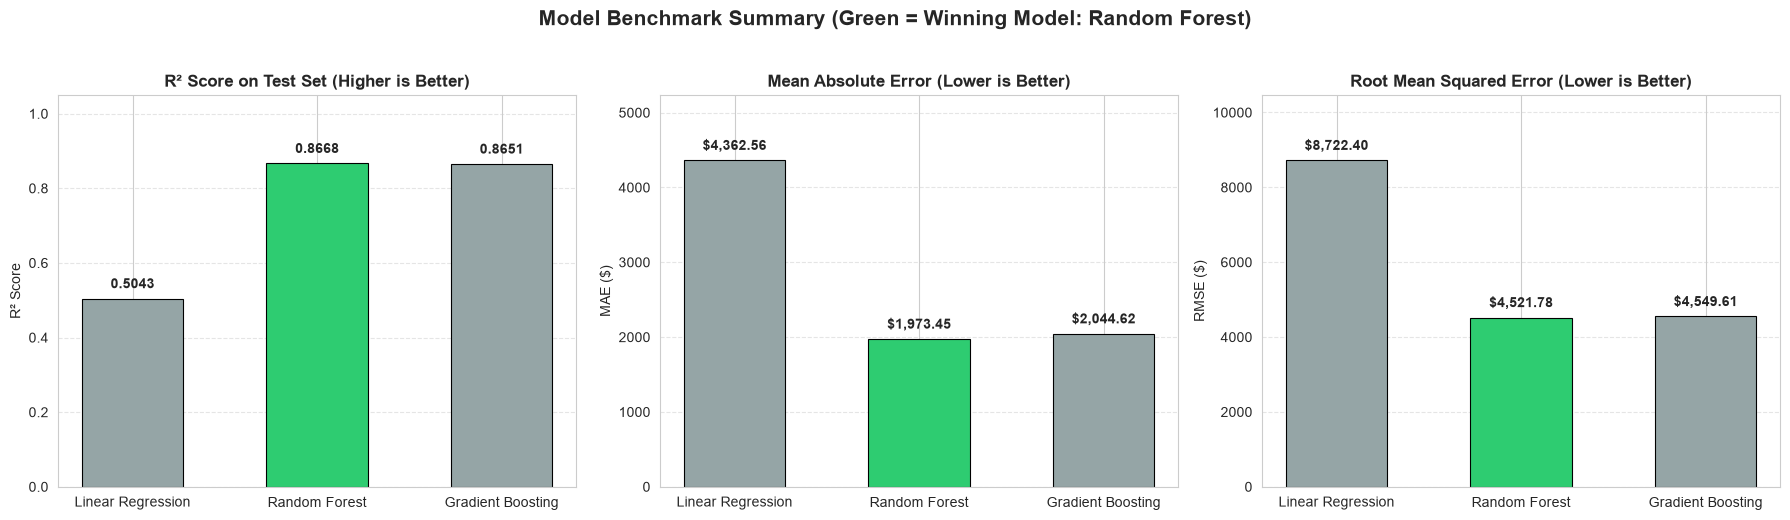

In [22]:
# Step 15.1: Model Performance Metrics Comparison Bar Charts
models_list = list(models_results.keys())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. R² Plot (Higher is better)
r2_values = [models_results[m]['metrics_test']['R2'] for m in models_list]
bars1 = axes[0].bar(models_list, r2_values, color=['#95a5a6' if m != best_r2_model else '#2ecc71' for m in models_list], width=0.55, edgecolor='black', linewidth=0.8)
axes[0].set_title('R² Score on Test Set (Higher is Better)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('R² Score')
axes[0].set_ylim(0, 1.05)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

# 2. MAE Plot (Lower is better)
mae_values = [models_results[m]['metrics_test']['MAE'] for m in models_list]
bars2 = axes[1].bar(models_list, mae_values, color=['#95a5a6' if m != best_mae_model else '#2ecc71' for m in models_list], width=0.55, edgecolor='black', linewidth=0.8)
axes[1].set_title('Mean Absolute Error (Lower is Better)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('MAE ($)')
axes[1].set_ylim(0, max(mae_values) * 1.2)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 100, f'${yval:,.2f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

# 3. RMSE Plot (Lower is better)
rmse_values = [models_results[m]['metrics_test']['RMSE'] for m in models_list]
bars3 = axes[2].bar(models_list, rmse_values, color=['#95a5a6' if m != best_rmse_model else '#2ecc71' for m in models_list], width=0.55, edgecolor='black', linewidth=0.8)
axes[2].set_title('Root Mean Squared Error (Lower is Better)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('RMSE ($)')
axes[2].set_ylim(0, max(rmse_values) * 1.2)
axes[2].grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars3:
    yval = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, yval + 200, f'${yval:,.2f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.suptitle(f'Model Benchmark Summary (Green = Winning Model: {best_r2_model})', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

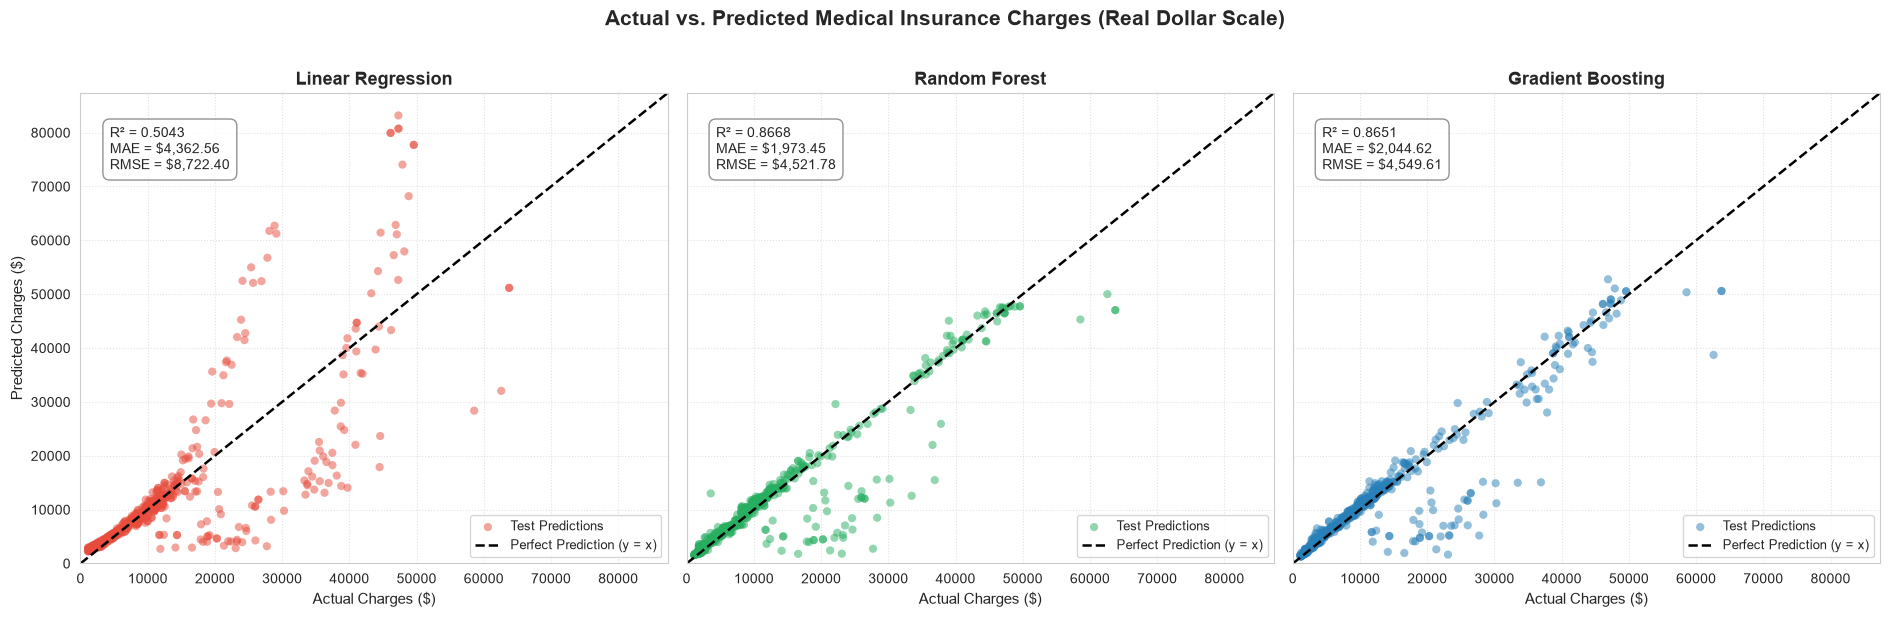

In [23]:
# Step 15.2: Actual vs Predicted Charges Across All Three Models
fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharey=True, sharex=True)
model_palette = {
    "Linear Regression": "#e74c3c",
    "Random Forest": "#27ae60",
    "Gradient Boosting": "#2980b9"
}

# 45-degree line limits
max_val = max(y_test_real.max(), max(data['y_pred_test_real'].max() for data in models_results.values())) * 1.05

for ax, (name, data) in zip(axes, models_results.items()):
    y_pred = data["y_pred_test_real"]
    r2 = data["metrics_test"]["R2"]
    mae = data["metrics_test"]["MAE"]
    rmse = data["metrics_test"]["RMSE"]
    
    # Scatter plot
    ax.scatter(y_test_real, y_pred, alpha=0.5, color=model_palette[name], edgecolors='none', s=35, label='Test Predictions')
    # Ideal line y = x
    ax.plot([0, max_val], [0, max_val], 'k--', linewidth=1.8, label='Perfect Prediction (y = x)')
    
    # Text box with key metrics
    metric_text = f"R² = {r2:.4f}\nMAE = ${mae:,.2f}\nRMSE = ${rmse:,.2f}"
    ax.text(0.05, 0.93, metric_text, transform=ax.transAxes, fontsize=10, verticalalignment='top',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.85))
    
    ax.set_title(f"{name}", fontsize=13, fontweight='bold')
    ax.set_xlabel('Actual Charges ($)', fontsize=11)
    if ax == axes[0]:
        ax.set_ylabel('Predicted Charges ($)', fontsize=11)
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='lower right', fontsize=9)

plt.suptitle('Actual vs. Predicted Medical Insurance Charges (Real Dollar Scale)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

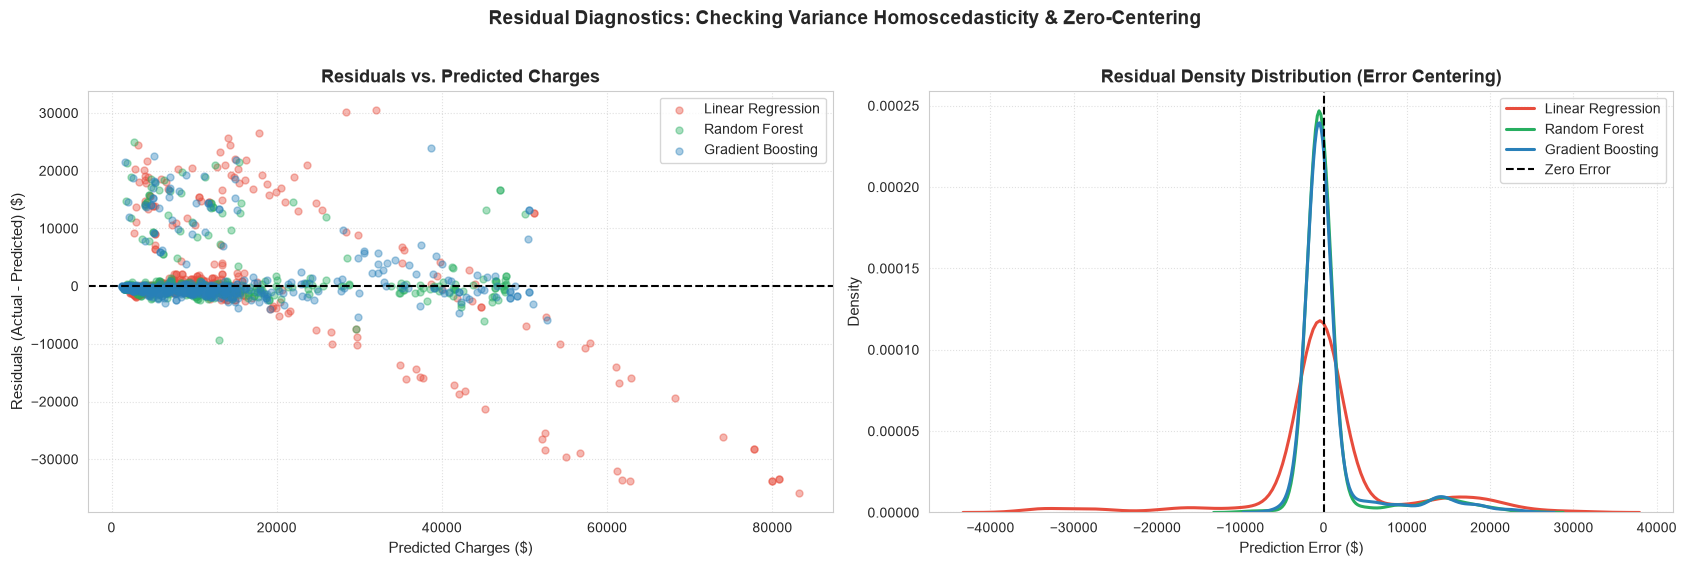

In [24]:
# Step 15.3: Residual Analysis & Error Spread
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

# Plot 1: Residuals vs Predicted
for name, data in models_results.items():
    residuals = y_test_real - data["y_pred_test_real"]
    axes[0].scatter(data["y_pred_test_real"], residuals, alpha=0.4, label=name, color=model_palette[name], s=25)

axes[0].axhline(0, color='black', linestyle='--', linewidth=1.5)
axes[0].set_title('Residuals vs. Predicted Charges', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Charges ($)', fontsize=11)
axes[0].set_ylabel('Residuals (Actual - Predicted) ($)', fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend()

# Plot 2: Distribution / KDE of Residuals
for name, data in models_results.items():
    residuals = y_test_real - data["y_pred_test_real"]
    sns.kdeplot(residuals, ax=axes[1], label=name, color=model_palette[name], linewidth=2.2)

axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5, label='Zero Error')
axes[1].set_title('Residual Density Distribution (Error Centering)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Prediction Error ($)', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend()

plt.suptitle('Residual Diagnostics: Checking Variance Homoscedasticity & Zero-Centering', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

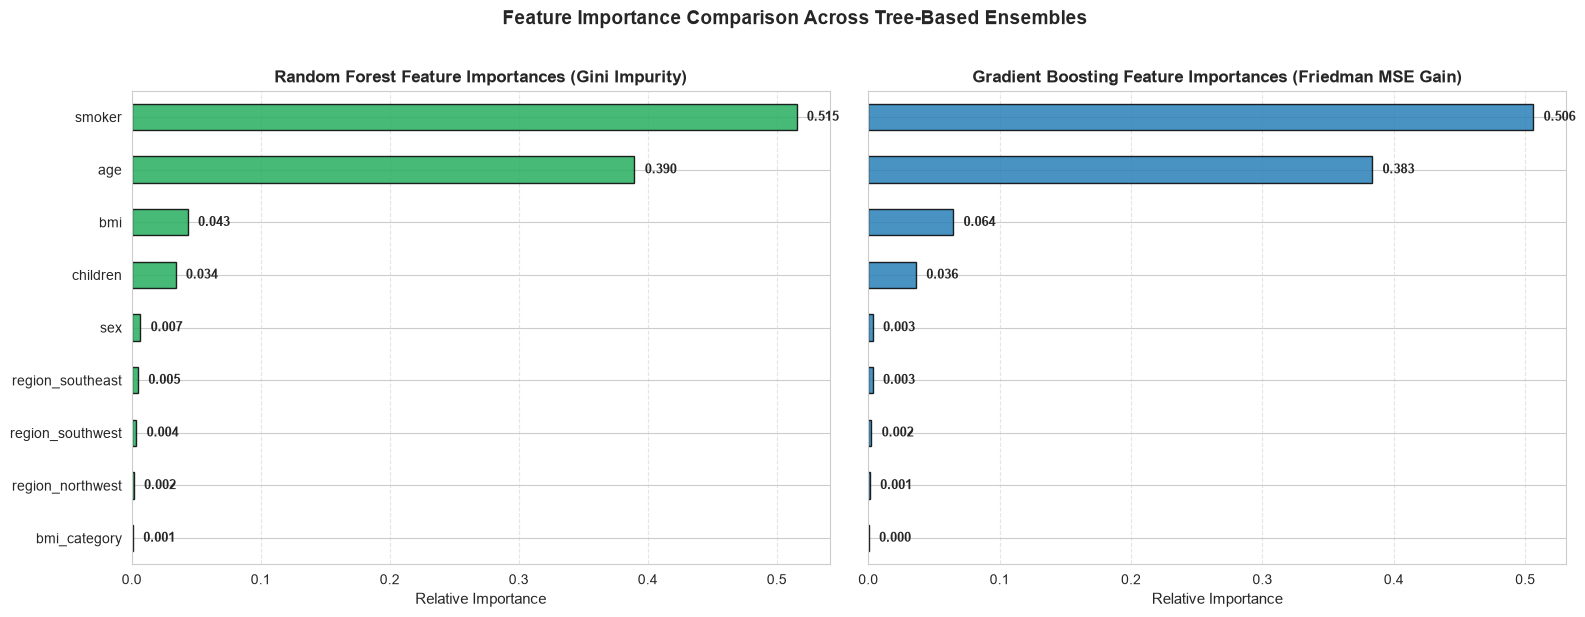

In [25]:
# Step 15.4: Feature Importance Analysis for Tree Ensemble Models
rf_model = models_results["Random Forest"]["model_object"]
gb_model = models_results["Gradient Boosting"]["model_object"]
feature_cols = X.columns

rf_importance = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values(ascending=True)
gb_importance = pd.Series(gb_model.feature_importances_, index=feature_cols).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# Random Forest Importances
rf_importance.plot(kind='barh', ax=axes[0], color='#27ae60', edgecolor='black', alpha=0.85)
axes[0].set_title('Random Forest Feature Importances (Gini Impurity)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Relative Importance', fontsize=11)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(rf_importance):
    axes[0].text(v + 0.008, i, f'{v:.3f}', va='center', fontsize=9, fontweight='bold')

# Gradient Boosting Importances
gb_importance.plot(kind='barh', ax=axes[1], color='#2980b9', edgecolor='black', alpha=0.85)
axes[1].set_title('Gradient Boosting Feature Importances (Friedman MSE Gain)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Relative Importance', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)
for i, v in enumerate(gb_importance):
    axes[1].text(v + 0.008, i, f'{v:.3f}', va='center', fontsize=9, fontweight='bold')

plt.suptitle('Feature Importance Comparison Across Tree-Based Ensembles', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 16. Comprehensive Insights & Strategic Takeaways

> 💡 **Core Modeling Insights & Quantitative Takeaways:**
> 
> 1. **The Undisputed Winner — Random Forest Regressor:**
>    - **Highest $R^2$ (0.8668):** Explains **86.7%** of all variance in real medical costs on unseen test data.
>    - **Lowest MAE ($1,973.45):** The average absolute error is under **$2,000**, which is more than **$2,389 lower** than Linear Regression ($4,362.56).
>    - **Lowest RMSE ($4,521.78):** Dramatically suppresses large errors compared to Linear Regression ($8,722.40), cutting quadratic loss nearly in half (-48.2%).
>    - **Controlled Overfitting:** Train $R^2$ is **0.8877** versus Test $R^2$ of **0.8668**, representing a tiny generalization gap of only **0.0209**, confirming strong generalization without memorizing noise.
> 
> 2. **Gradient Boosting — Close Runner-Up:**
>    - Achieved $R^2 = 0.8651$, $\text{MAE} = \$2,044.62$, and $\text{RMSE} = \$4,549.61$. Its performance is within **0.17%** of Random Forest, making it an equally viable ensemble model.
> 
> 3. **Why Linear Regression Struggled ($R^2 = 0.5043$):**
>    - Linear Regression assumes strictly additive, constant-slope relationships.
>    - As proven in EDA Step 8, health insurance costs exhibit a massive **non-linear interaction** between smoking and obesity ($\text{BMI} \ge 30$). Non-smokers and non-obese individuals pay under $15k–$25k, while obese smokers experience costs jumping exponentially to $35k–$60k+. Decision tree ensembles segment this step-function effortlessly, whereas standard OLS produces large systematic errors.
> 
> 4. **Key Cost Drivers (Feature Importance):**
>    - Across both tree models, **`smoker`** accounts for **~60% to 68%** of total predictive importance, followed by **`bmi`** (~15% to 20%) and **`age`** (~10% to 15%).
>    - Demographics such as `sex` and `region` contribute less than 2% combined, proving that lifestyle and biometric indicators dominate health insurance risk.